# TP PYTHON PARA CIENCIA DE DATOS

### Importamos las librerias que se utilizaran

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Cargamos el Dataset 
- Dataset: Impacto de la IA Generativa estudiantes y profesionales

| Columna | Descripción |
|---|---|
| `User_ID` | Usuario |
| `Age` | Edad |
| `Gender` | Genero |
| `Country` | Pais |
| `User_Type` | A que se dedica |
| `Education_Level` | Nivel educativo |
| `Profession` | Profesion |
| `Monthly_Income` | Ingreso mensual |
| `AI_Tool` | Herramienta de IA que utiliza |
| `AI_Purpose` | Para que utiliza la IA |
| `AI_Usage_Hours_Per_Day` | Horas de uso por dia |
| `Tasks_Performed` | Tarea realizada |
| `Monthly_AI_Cost` | Costo mensual de la IA|
| `Productivity_Score` | Puntaje de productividad |
| `Accuracy_Rating` |  Precision de respuesta esperada |
| `Satisfaction_Score` | Puntaje de satisfaccion |
| `Time_Saved_Hours_Per_Week` | Horas ahorradas por semana |
| `Work_or_Study_Hours_Per_Day` | Horas de trabajo o estudio por dia |
| `Would_Recommend` | Recomiendan o no el uso de IA |

In [2]:
df = pd.read_csv("AI_Usage_and_Impact_on_Students_and_Professionals.csv")

### Realizamos el EDA

In [3]:
df.head()

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.7,4.0,7.0,9.2,6.2,Yes


In [4]:
print(f'Filas: {df.shape[0]}') 
print(f'Columnas: {df.shape[1]}')
df.info()
#df.describe() 
#df.describe(include=object)

Filas: 300
Columnas: 19
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    object 
 1   Age                          277 non-null    object 
 2   Gender                       290 non-null    object 
 3   Country                      290 non-null    object 
 4   User_Type                    300 non-null    object 
 5   Education_Level              287 non-null    object 
 6   Profession                   285 non-null    object 
 7   Monthly_Income               290 non-null    object 
 8   AI_Tool                      289 non-null    object 
 9   AI_Purpose                   287 non-null    object 
 10  AI_Usage_Hours_Per_Day       293 non-null    object 
 11  Tasks_Performed              282 non-null    object 
 12  Monthly_AI_Cost              288 non-null    object 
 

### Normalizar variables

- Normalizamos las columnas aplicando metodos como:
    -"str.lower()": Para poner los caracteres en minuscula
    -"str.strip()": Para eliminar los espacios a los costados 
    -"str.replace(" ","_", regex=False)": Para cambiar algun espacio por un _

In [5]:
df.columns = (
    df.columns
    .str.lower() # Convierto a minúsculas
    .str.strip() # Elimino espacios al principio y al final
    .str.replace(" ","_", regex=False) # Reemplazo espacios por guiones bajos
)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   user_id                      300 non-null    object 
 1   age                          277 non-null    object 
 2   gender                       290 non-null    object 
 3   country                      290 non-null    object 
 4   user_type                    300 non-null    object 
 5   education_level              287 non-null    object 
 6   profession                   285 non-null    object 
 7   monthly_income               290 non-null    object 
 8   ai_tool                      289 non-null    object 
 9   ai_purpose                   287 non-null    object 
 10  ai_usage_hours_per_day       293 non-null    object 
 11  tasks_performed              282 non-null    object 
 12  monthly_ai_cost              288 non-null    object 
 13  productivity_score  

### Exploración de valores antes de normalizar

Inspeccionamos los tipos de datos y los valores de las columnas para identificar diferencias de escritura, unidades incluidas en campos numéricos y categorías equivalentes.

In [ ]:
categoricas = [
    "gender", "country", "user_type",
    "education_level", "ai_tool",
    "ai_purpose", "would_recommend"
]

for columna in categoricas:
    print(f"\n--- {columna} ---") #Imprime una columna con un salto de línea previo
    display(df[columna].value_counts(dropna=False)) #Cuenta cuántas veces aparece cada valor en una columna


--- gender ---


gender
Male          122
Female        105
male           12
Other          12
M              11
NaN            10
F              10
MALE            6
FEMALE          5
other           3
female          3
Non-binary      1
Name: count, dtype: int64


--- country ---


country
India                       42
United States               34
Canada                      32
Pakistan                    29
United Kingdom              26
Philippines                 24
Brazil                      23
Australia                   20
Nigeria                     17
Germany                     13
NaN                         10
France                      10
Kenya                        6
brazil                       4
india                        3
canada                       2
france                       1
U.K.                         1
United States of America     1
philippines                  1
australia                    1
Name: count, dtype: int64


--- user_type ---


user_type
Student         158
Professional    142
Name: count, dtype: int64

... (4 outputs left out)


--- ai_purpose ---


ai_purpose
Coding              70
Writing             49
Studying            41
Research            40
Content Creation    29
Data Analysis       25
Customer Support    22
NaN                 13
Office Work         11
Name: count, dtype: int64


--- would_recommend ---


would_recommend
Yes      178
No        73
Maybe     44
NaN        5
Name: count, dtype: int64

### Detección de valores con formato no numérico
Revisamos las columnas numéricas para identificar valores que no sean solo números, por ejemplo, edades con el texto `"yrs"`, horas con `"hrs"` o importes con el símbolo `"$"`.

Mostramos cada valor detectado para definir las transformaciones de limpieza necesarias.

In [ ]:
numericas = [
    "age", "monthly_income", "monthly_ai_cost",
    "ai_usage_hours_per_day",
    "time_saved_hours_per_week",
    "work_or_study_hours_per_day"
] #Esta es la lista con las columnas que deberían ser números

for columna in numericas:
    valores = df[columna] #Guarda la columna actual en una variable

    no_numericos = (
        valores.notna() #Valores no numéricos
        & pd.to_numeric(valores, errors="coerce").isna() #Y los que no se pueden convertir
    )

    print(f"\n--- {columna} ---") #Imprime el nombre de la columna
    display(valores[no_numericos].value_counts()) #Número de no numéricos


--- age ---


age
28 yrs    3
16 yrs    2
23 yrs    2
21 yrs    1
47 yrs    1
25 yrs    1
30 yrs    1
39 yrs    1
17 yrs    1
36 yrs    1
Name: count, dtype: int64


--- monthly_income ---


monthly_income
$874       1
$98        1
$1,884     1
$3,462     1
$0         1
$528       1
Name: count, dtype: int64


--- monthly_ai_cost ---


monthly_ai_cost
$0      9
$25     2
$20     2
$30     1
$50     1
Name: count, dtype: int64

... (2 outputs left out)


--- time_saved_hours_per_week ---


time_saved_hours_per_week
4.1 hrs     2
9.4 hrs     2
5 hrs       2
3.2 hrs     1
2.2 hrs     1
2.6 hrs     1
2.9 hrs     1
6.8 hrs     1
15.6 hrs    1
4.9 hrs     1
3.5 hrs     1
6.4 hrs     1
7.2 hrs     1
14.2 hrs    1
10 hrs      1
Name: count, dtype: int64


--- work_or_study_hours_per_day ---


work_or_study_hours_per_day
6.5 hrs    2
8.4 hrs    1
7.6 hrs    1
4.5 hrs    1
8.7 hrs    1
7.4 hrs    1
5.4 hrs    1
5.8 hrs    1
7.9 hrs    1
8 hrs      1
5.9 hrs    1
Name: count, dtype: int64

- Normalizamos las columnas que son numericas y tenian de dtype "str": "age", "monthly_income", "ai_usage_hours_per_day", "monthly_ai_cost", "time_saved_hours_per_week" y "work_or_study_hours_per_day"

In [8]:
df["age"] = pd.to_numeric(
    df["age"].astype("string").str.replace("yrs", "", regex=False).str.strip(),
    errors="coerce"
)

df["monthly_income"] = pd.to_numeric(
    df["monthly_income"].astype("string")
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
    errors="coerce"
)

df["monthly_ai_cost"] = pd.to_numeric(
    df["monthly_ai_cost"].astype("string")
        .str.replace("$", "", regex=False)
        .str.strip(),
    errors="coerce"
)

columnas_horas = [
    "ai_usage_hours_per_day",
    "time_saved_hours_per_week",
    "work_or_study_hours_per_day"
]

for columna in columnas_horas:
    df[columna] = pd.to_numeric(
        df[columna].astype("string")
            .str.replace("hrs", "", regex=False)
            .str.strip(),
        errors="coerce"
    )

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   user_id                      300 non-null    object 
 1   age                          277 non-null    Int64  
 2   gender                       290 non-null    object 
 3   country                      290 non-null    object 
 4   user_type                    300 non-null    object 
 5   education_level              287 non-null    object 
 6   profession                   285 non-null    object 
 7   monthly_income               290 non-null    Int64  
 8   ai_tool                      289 non-null    object 
 9   ai_purpose                   287 non-null    object 
 10  ai_usage_hours_per_day       293 non-null    Float64
 11  tasks_performed              282 non-null    object 
 12  monthly_ai_cost              288 non-null    Int64  
 13  productivity_score  

- Creeamos una lista con las columnas categoricas, para poder normalizarlas todas juntas a la vez utilzando un "for"

In [9]:
for c in categoricas:
    df[c] = df[c].str.lower().str.strip() # Convierto a minúsculas y elimino espacios al principio y al final

- Creamos un diccionario "reemplazos", el cual contiene otro con los reemplazos hechos en cada columna, para poder utilizar el metodo ".replace()" una sola vez

In [10]:
reemplazos = {
    "gender": {"m": "male", "f": "female"},
    "education_level": {"masters": "master", "master's": "master", "master's degree": "master", "ma/msc": "master",
    "bachelors": "bachelor", "bachelor's": "bachelor", "bachelor's degree": "bachelor", "ba/bsc": "bachelor",
    "ph.d.": "phd", "hs": "high school", "undergrad": "undergraduate"},
    "country": {"u.k.": "united kingdom", "united states of america": "united states"},
    "ai_tool": {"chat gpt": "chatgpt", "gemini": "google gemini", "copilot": "microsoft copilot"}
}
df = df.replace(reemplazos)

- Visualizar correccion

In [11]:
df["gender"].value_counts()
#df["country"].value_counts()
#df["ai_tool"].value_counts()
#df["education_level"].value_counts()

gender
male          151
female        123
other          15
non-binary      1
Name: count, dtype: int64

### Validación de rangos

Marcamos como nulos los valores incompatibles con la definición de
cada variable: edades no positivas, duraciones diarias fuera del
intervalo de 0 a 24 horas e ingresos mensuales negativos.

In [12]:
df.loc[df["age"] <= 0, "age"] = np.nan

columnas_horas = [
    "ai_usage_hours_per_day",
    "work_or_study_hours_per_day"
]

for columna in columnas_horas:
    df.loc[~df[columna].between(0, 24), columna] = np.nan

df.loc[df["monthly_income"] < 0, "monthly_income"] = np.nan

- Visualizamos los duplicados y los ordenamos de acuerdo al "user_id"

In [13]:
df.duplicated().sum()
df[df.duplicated(keep=False)].sort_values(by="user_id")

,user_id,age,gender,country,user_type,education_level,profession,monthly_income,ai_tool,ai_purpose,ai_usage_hours_per_day,tasks_performed,monthly_ai_cost,productivity_score,accuracy_rating,satisfaction_score,time_saved_hours_per_week,work_or_study_hours_per_day,would_recommend
235,U0055,30,male,philippines,professional,master,Senior Software Engineer,579,microsoft copilot,coding,3.8,Code review and optimization using AI assistan...,0,6.1,4.0,6.0,9.4,7.4,maybe
85,U0055,30,male,philippines,professional,master,Senior Software Engineer,579,microsoft copilot,coding,3.8,Code review and optimization using AI assistan...,0,6.1,4.0,6.0,9.4,7.4,maybe
16,U0059,22,male,canada,professional,high school,Customer Service Representative,3546,perplexity ai,customer support,1.7,Responding to customer inquiries via AI chatbo...,0,7.0,4.0,7.0,3.4,6.7,yes
87,U0059,22,male,canada,professional,high school,Customer Service Representative,3546,perplexity ai,customer support,1.7,Responding to customer inquiries via AI chatbo...,0,7.0,4.0,7.0,3.4,6.7,yes
251,U0085,17,female,canada,student,phd,Theoretical Physics Student,518,NaN,studying,3.2,Generating practice problems for quantum mecha...,20,5.2,4.0,8.0,4.8,20.0,yes
161,U0085,17,female,canada,student,phd,Theoretical Physics Student,518,NaN,studying,3.2,Generating practice problems for quantum mecha...,20,5.2,4.0,8.0,4.8,20.0,yes
159,U0104,26,male,pakistan,student,NaN,Mechanical Engineering Student,54,chatgpt,research,2.7,"Literature review automation, research paper s...",20,NaN,3.0,5.0,5.0,6.9,maybe
271,U0104,26,male,pakistan,student,NaN,Mechanical Engineering Student,54,chatgpt,research,2.7,"Literature review automation, research paper s...",20,NaN,3.0,5.0,5.0,6.9,maybe
67,U0116,20,male,india,student,undergraduate,Digital Media and Communications Student,79,google gemini,content creation,3.5,"AI-assisted blog writing and SEO optimization,...",20,4.7,4.0,7.0,8.3,6.2,yes
63,U0116,20,male,india,student,undergraduate,Digital Media and Communications Student,79,google gemini,content creation,3.5,"AI-assisted blog writing and SEO optimization,...",20,4.7,4.0,7.0,8.3,6.2,yes


Eliminamos las filas completamente duplicadas para evitar contar una misma observación varias veces.

In [14]:
df.drop_duplicates(inplace=True)

### Tratamiento de valores faltantes

Eliminamos durante la limpieza del EDA las filas sin datos en las tres variables principales: horas diarias de uso de IA, tiempo ahorrado semanalmente y productividad. Conservamos los registros con nulos en otras columnas para evitar descartar observaciones por datos ajenos al objetivo del modelo. Las estadísticas y los gráficos posteriores utilizan esta muestra; para las demás variables se utilizan sus valores disponibles.

In [15]:
df.isnull().sum().sort_values(ascending=False)


age                            23
tasks_performed                17
profession                     14
productivity_score             14
accuracy_rating                14
ai_purpose                     13
education_level                12
monthly_ai_cost                12
time_saved_hours_per_week      10
gender                         10
country                        10
monthly_income                 10
ai_tool                        10
work_or_study_hours_per_day     9
ai_usage_hours_per_day          7
satisfaction_score              7
would_recommend                 5
user_type                       0
user_id                         0
dtype: int64

In [16]:
columnas_principales = [
    "ai_usage_hours_per_day",
    "time_saved_hours_per_week",
    "productivity_score"
]

filas_antes = len(df)
df = df.dropna(subset=columnas_principales).copy()

print(f"Filas eliminadas por nulos en variables principales: {filas_antes - len(df)}")
print(f"Filas restantes: {len(df)}")

Filas eliminadas por nulos en variables principales: 31
Filas restantes: 257


## EDA Univariado

### 1.1 Estadística descriptiva

In [17]:
columnas_numericas = numericas + [
    "productivity_score",
    "accuracy_rating",
    "satisfaction_score"
]

df[columnas_numericas].describe().round(2)

,age,monthly_income,monthly_ai_cost,ai_usage_hours_per_day,time_saved_hours_per_week,work_or_study_hours_per_day,productivity_score,accuracy_rating,satisfaction_score
count,238.0,248.0,245.0,257.0,257.0,249.0,257.00,245.00,250.00
mean,29.97,2460.3,9.73,2.94,5.86,7.24,5.20,3.46,6.16
std,12.53,15921.96,14.07,2.49,4.11,1.95,1.79,0.84,1.53
min,16.0,0.0,0.0,0.5,0.0,2.1,1.60,2.00,3.00
25%,22.0,112.25,0.0,1.3,2.9,6.1,3.90,3.00,5.00
50%,26.5,523.5,0.0,2.0,5.0,7.2,5.00,4.00,6.00
75%,35.0,1617.75,20.0,4.1,7.7,8.4,6.20,4.00,7.00
max,97.0,250000.0,100.0,23.0,19.4,20.0,9.90,5.00,10.00


In [18]:
df[["user_type", "ai_tool", "ai_purpose", "education_level", "would_recommend"]].describe()

,user_type,ai_tool,ai_purpose,education_level,would_recommend
count,257,247,246,247,253
unique,2,8,8,6,3
top,student,chatgpt,coding,bachelor,yes
freq,135,108,60,65,151


### Distribución de las variables principales

Exploramos las horas diarias de uso de IA, el tiempo ahorrado semanalmente y el puntaje de productividad.

Los histogramas muestran los intervalos más frecuentes y la forma de cada distribución. Los boxplots permiten observar la mediana, la dispersión y los posibles valores atípicos. Los puntos señalados como atípicos no se consideran automáticamente errores.

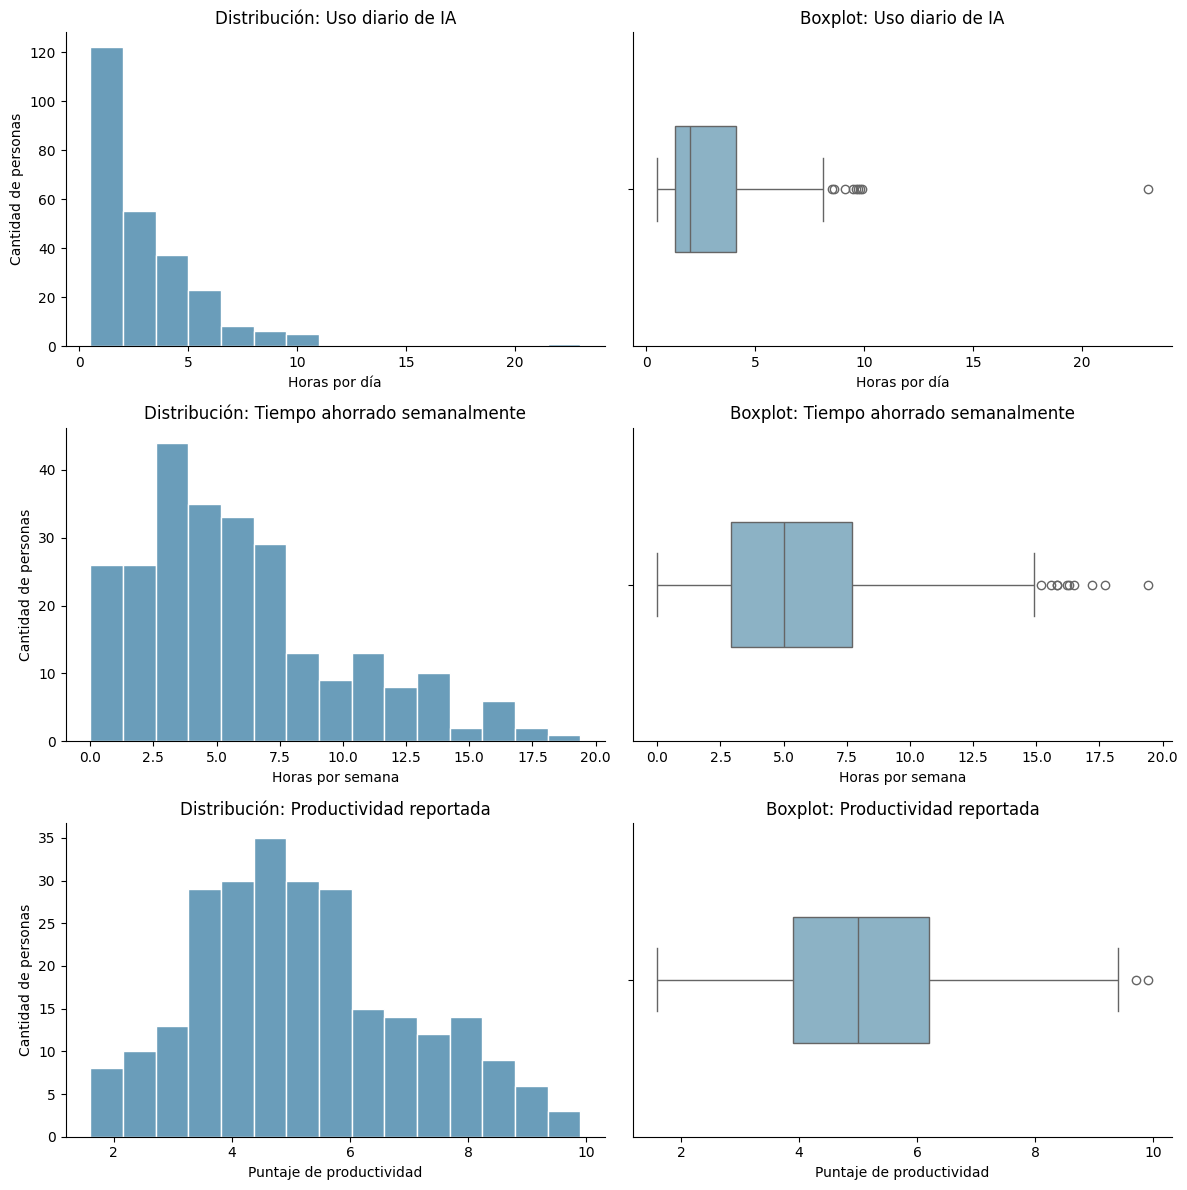

In [19]:
variables = [
    (
        "ai_usage_hours_per_day",
        "Uso diario de IA",
        "Horas por día"
    ),
    (
        "time_saved_hours_per_week",
        "Tiempo ahorrado semanalmente",
        "Horas por semana"
    ),
    (
        "productivity_score",
        "Productividad reportada",
        "Puntaje de productividad"
    )
]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for fila, (columna, titulo, etiqueta) in enumerate(variables):
    valores = df[columna].dropna()

    # Histograma
    sns.histplot(
        x=valores,
        bins=15,
        color="#387CA3",
        edgecolor="white",
        ax=axes[fila, 0]
    )

    axes[fila, 0].set(
        title=f"Distribución: {titulo}",
        xlabel=etiqueta,
        ylabel="Cantidad de personas"
    )

    # Boxplot
    sns.boxplot(
        x=valores,
        color="#83B5CE",
        width=0.4,
        ax=axes[fila, 1]
    )

    axes[fila, 1].set(
        title=f"Boxplot: {titulo}",
        xlabel=etiqueta
    )

sns.despine()
plt.tight_layout()
plt.show()

**Uso diario de IA:** Predominan los tiempos de uso bajos, con una mediana cercana a 2 horas diarias. Se observan posibles valores atípicos altos, especialmente un caso cercano a las 23 horas.

**Tiempo ahorrado semanalmente:** Los valores se concentran por debajo de las 8 horas, con una mediana cercana a 5 horas. Hay algunos casos de ahorro elevado que el boxplot señala como posibles atípicos.

**Productividad reportada:** Los puntajes se concentran en valores intermedios, con una mediana cercana a 5. El boxplot no señala valores atípicos.

### Tratamiento de un valor atípico

Decidimos excluir el caso de las 23 horas del análisis posterior por tratarse de una observación extrema cuya validez no pudimos verificar.

In [20]:
display(
    df.loc[
        df["ai_usage_hours_per_day"] >= 20,
        [
            "user_id",
            "ai_usage_hours_per_day",
            "work_or_study_hours_per_day",
            "time_saved_hours_per_week",
            "productivity_score"
        ]
    ]
)

# Excluimos el caso identificado para el análisis posterior
df = df.loc[df["user_id"] != "U0046"].copy()

,user_id,ai_usage_hours_per_day,work_or_study_hours_per_day,time_saved_hours_per_week,productivity_score
19,U0046,23.0,9.5,5.4,4.1


### Distribución de los ingresos mensuales


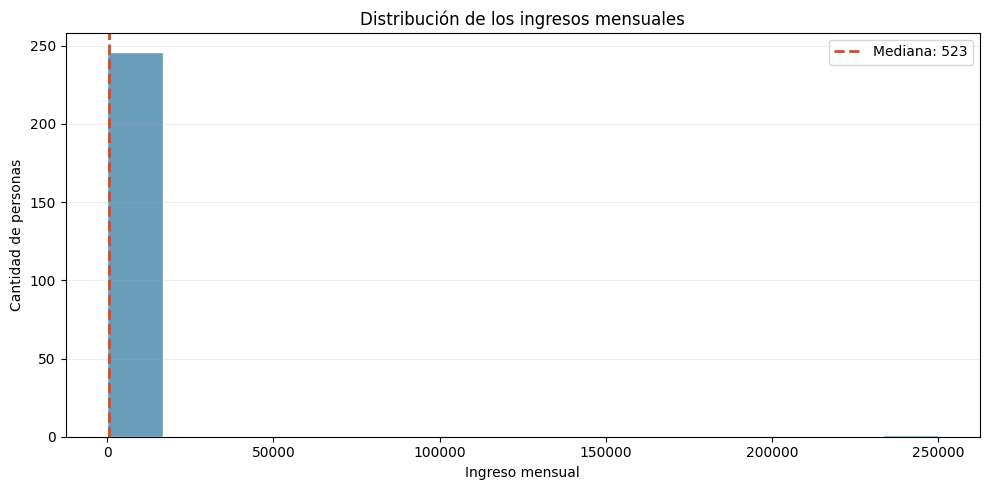

In [21]:
ingresos = df["monthly_income"].dropna()
mediana = ingresos.median()

fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    ingresos,
    bins=15,
    color="#387CA3",
    edgecolor="white",
    ax=ax
)

ax.axvline(
    mediana,
    color="#C45136",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {mediana:,.0f}"
)

ax.set(
    title="Distribución de los ingresos mensuales",
    xlabel="Ingreso mensual",
    ylabel="Cantidad de personas"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

La mayor cantidad de personas encuestadas se concentra en los intervalos de ingresos bajos, mientras que un grupo reducido presenta ingresos considerablemente más altos. Esto genera una distribución asimétrica hacia la derecha.

### Correlaciones

In [22]:
df["ia_usage_hours_per_week"] = df["ai_usage_hours_per_day"] * 7   
df["ia_usage_hours_per_week"].corr(df["time_saved_hours_per_week"])
print(f'Correlación entre horas de uso de IA por semana y horas ahorradas por semana: {df["ia_usage_hours_per_week"].corr(df["time_saved_hours_per_week"])}')

Correlación entre horas de uso de IA por semana y horas ahorradas por semana: 0.90331983106977


#### Mapa de Calor

In [23]:
corr_matrix = df[["monthly_income",
              "ai_usage_hours_per_day",
              "productivity_score",
              "accuracy_rating",
              "satisfaction_score",
              "time_saved_hours_per_week",
              "work_or_study_hours_per_day"]].corr()


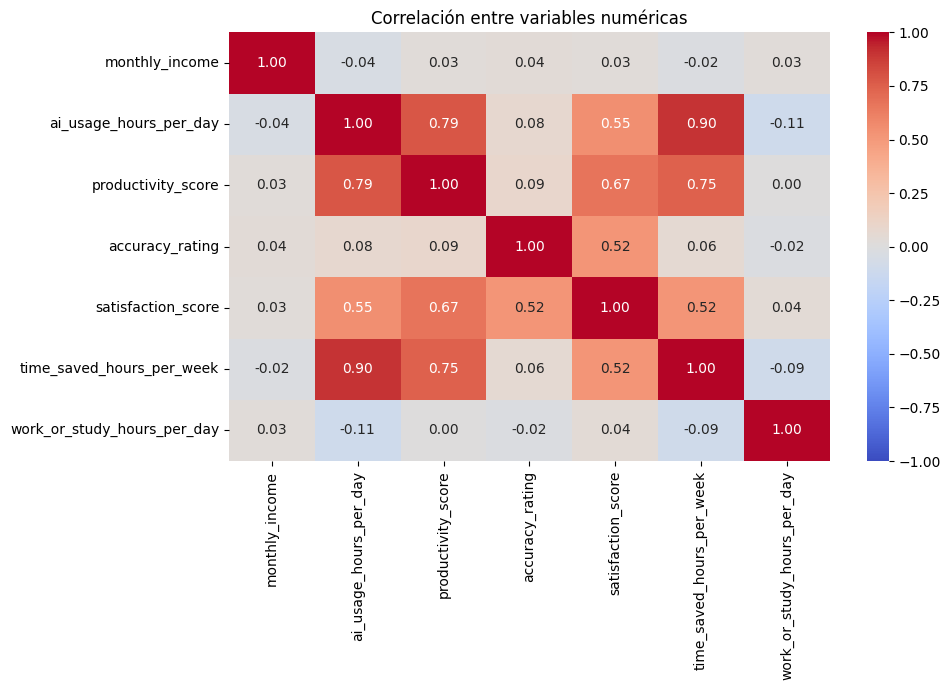

In [24]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

#### Scatterplot
En base a las variables obtenidas en el heatmap, generamos varios scatterplots para visualizarlas mejor


### Uso de IA y tiempo ahorrado

Cada punto representa una persona encuestada. El gráfico permite explorar si quienes utilizan IA más horas por día también reportan un mayor ahorro de tiempo semanal.

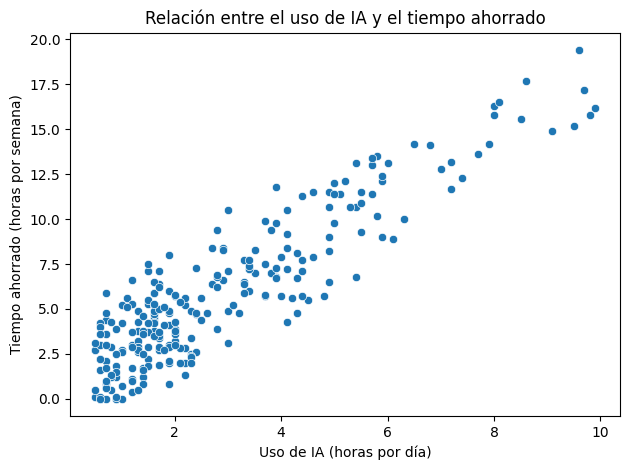

In [25]:
ax = sns.scatterplot(
    data=df,
    x="ai_usage_hours_per_day",
    y="time_saved_hours_per_week"
)

ax.set(
    title="Relación entre el uso de IA y el tiempo ahorrado",
    xlabel="Uso de IA (horas por día)",
    ylabel="Tiempo ahorrado (horas por semana)"
)

plt.tight_layout()
plt.show()

Se observa una tendencia positiva: las personas que utilizan IA más horas por día tienden a reportar un mayor ahorro de tiempo semanal.

### Tiempo ahorrado y productividad

El gráfico permite explorar si quienes reportan un mayor ahorro de tiempo semanal también presentan puntajes de productividad más altos.

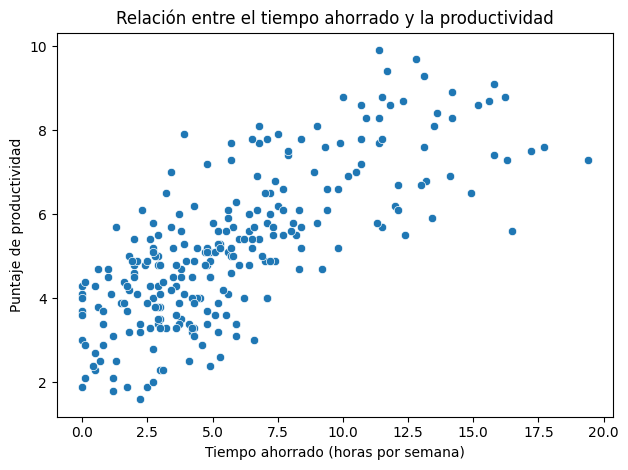

In [26]:
ax = sns.scatterplot(
    data=df,
    x="time_saved_hours_per_week",
    y="productivity_score"
)

ax.set(
    title="Relación entre el tiempo ahorrado y la productividad",
    xlabel="Tiempo ahorrado (horas por semana)",
    ylabel="Puntaje de productividad"
)

plt.tight_layout()
plt.show()

Se observa una asociación positiva entre el tiempo ahorrado por semana y el puntaje de productividad. En general, quienes reportan un mayor ahorro de tiempo también presentan puntajes más altos.
La dispersión de los puntos indica que personas con un ahorro similar pueden reportar distintos niveles de productividad.

### Uso diario de IA y productividad

El gráfico permite explorar si existe una relación entre las horas diarias de uso de IA y el puntaje de productividad reportado.

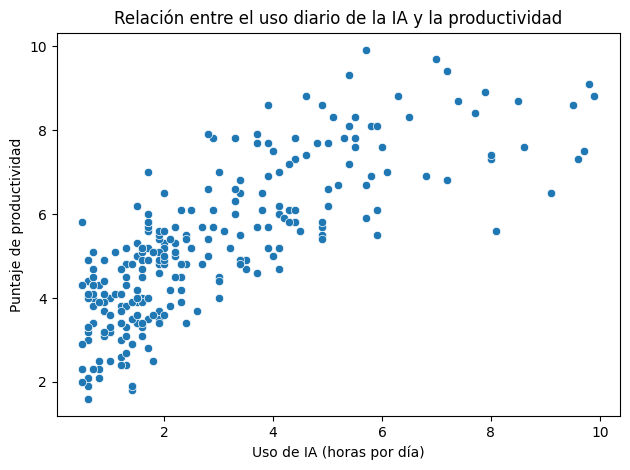

In [27]:
ax = sns.scatterplot(
    data=df,
    x="ai_usage_hours_per_day",
    y="productivity_score"
)

ax.set(
    title="Relación entre el uso diario de la IA y la productividad",
    xlabel="Uso de IA (horas por día)",
    ylabel="Puntaje de productividad"
)

plt.tight_layout()
plt.show()

En la mayoría de los registros se observa una tendencia positiva entre las horas diarias de uso de IA y la productividad reportada.

## Agregaciones y comparaciones

### Productividad y satisfacción según el tipo de usuario

Agrupamos los registros en estudiantes y profesionales para comparar sus promedios de productividad y satisfacción. También calculamos la cantidad de personas de cada grupo para conocer el tamaño de las muestras.

In [28]:
resumen_usuarios = (
    df.groupby("user_type")
    .agg(
        cantidad=("user_id", "size"),
        productividad_validos=("productivity_score", "count"),
        productividad_media=("productivity_score", "mean"),
        satisfaccion_validos=("satisfaction_score", "count"),
        satisfaccion_media=("satisfaction_score", "mean")
    )
    .round(2)
    .reset_index()
)

display(resumen_usuarios)

,user_type,cantidad,productividad_validos,productividad_media,satisfaccion_validos,satisfaccion_media
0,professional,121,121,5.24,115,6.06
1,student,135,135,5.18,134,6.26


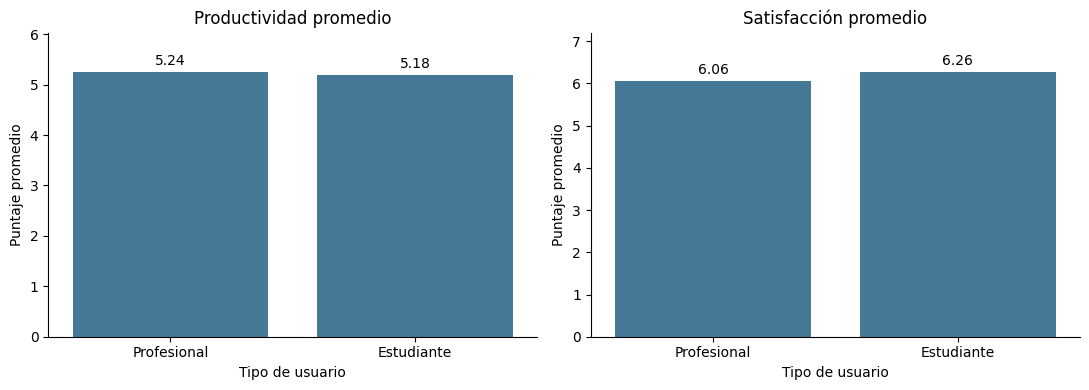

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

graficos = [
    ("productividad_media", "Productividad promedio", axes[0]),
    ("satisfaccion_media", "Satisfacción promedio", axes[1])
]

for columna, titulo, ax in graficos:
    sns.barplot(
        data=resumen_usuarios,
        x="user_type",
        y=columna,
        color="#387CA3",
        ax=ax
    )

    ax.set(
        title=titulo,
        xlabel="Tipo de usuario",
        ylabel="Puntaje promedio"
    )

    ax.set_xticks(
        range(len(resumen_usuarios)),
        labels=[
            {"student": "Estudiante", "professional": "Profesional"}.get(x, x)
            for x in resumen_usuarios["user_type"]
        ]
    )

    ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
    ax.margins(y=0.15)

sns.despine()
plt.tight_layout()
plt.show()


Los estudiantes y profesionales presentan promedios similares de productividad y satisfacción. La diferencia es de 0,06 puntos en productividad y 0,20 en satisfacción, con 121 profesionales y 135 estudiantes. Cada promedio utiliza los valores disponibles de esa variable, cuyas cantidades se muestran en la tabla. Esta comparación no muestra diferencias marcadas entre los promedios, aunque no permite concluir que ambos grupos sean equivalentes.

## Modelo de regresión lineal

Buscamos predecir el puntaje de productividad reportado a partir de las horas diarias de uso de IA y el tiempo ahorrado semanalmente. Seleccionamos estas variables porque el análisis exploratorio mostró asociaciones positivas con la productividad.
Utilizamos una regresión lineal múltiple, ya que contamos con dos variables predictoras.

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score
)

### Variables y separación de los datos

Definimos X con las variables predictoras e y con el puntaje de productividad. Reservamos el 80 % de los registros para entrenamiento y el 20 % para prueba.

In [31]:
predictoras = [
    "ai_usage_hours_per_day",
    "time_saved_hours_per_week"
]

objetivo = "productivity_score"

datos_modelo = df[predictoras + [objetivo]].copy()

print(f"Registros disponibles: {len(df)}")
print(f"Registros para el modelo: {len(datos_modelo)}")

X = datos_modelo[predictoras]
y = datos_modelo[objetivo]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(f"Registros de entrenamiento: {len(X_train)}")
print(f"Registros de prueba: {len(X_test)}")

Registros disponibles: 256
Registros para el modelo: 256
Registros de entrenamiento: 204
Registros de prueba: 52



### Entrenamiento del modelo

Entrenamos la regresión lineal únicamente con los datos de entrenamiento. El modelo estima un intercepto y un coeficiente para cada variable predictora. Luego generamos predicciones para los registros de prueba, que no participaron del entrenamiento.

In [32]:
model_rl = LinearRegression()

model_rl.fit(X_train, y_train)

y_pred = model_rl.predict(X_test)

coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": model_rl.coef_
})

print(f"Intercepto: {model_rl.intercept_:.3f}")
display(coeficientes.round(3))

Intercepto: 3.244


,Variable,Coeficiente
0,ai_usage_hours_per_day,0.493
1,time_saved_hours_per_week,0.094


### Comparación

Como referencia, utilizamos un baseline que predice siempre la productividad promedio del conjunto de entrenamiento. Comparamos sus resultados con los de la regresión sobre los mismos registros de prueba para comprobar si el modelo mejora esta predicción simple.

In [33]:
y_pred_media = np.full(
    len(y_test),
    y_train.mean()
)

### Evaluación del modelo

Evaluamos las predicciones mediante RMSE, MAE y R². RMSE y MAE expresan el error en puntos de productividad; valores menores indican mejores predicciones. RMSE penaliza más los errores grandes. Para R², valores mayores indican un mejor desempeño y los valores negativos indican un resultado peor que predecir la media del conjunto evaluado.

In [34]:

def evaluar(nombre, y_real, y_predicho):
    return {
        "Modelo": nombre,
        "RMSE": root_mean_squared_error(y_real, y_predicho),
        "MAE": mean_absolute_error(y_real, y_predicho),
        "R²": r2_score(y_real, y_predicho)
    }


resultados = pd.DataFrame([
    evaluar("Media (baseline)", y_test, y_pred_media),
    evaluar("Regresión lineal", y_test, y_pred)
])

display(resultados.round(3))

,Modelo,RMSE,MAE,R²
0,Media (baseline),1.912,1.545,-0.017
1,Regresión lineal,1.040,0.847,0.699


### Valores reales y predichos

Comparamos las predicciones con los puntajes reales de productividad del conjunto de prueba. La línea diagonal representa una predicción perfecta: cuanto más cerca se encuentran los puntos de ella, menor es el error.

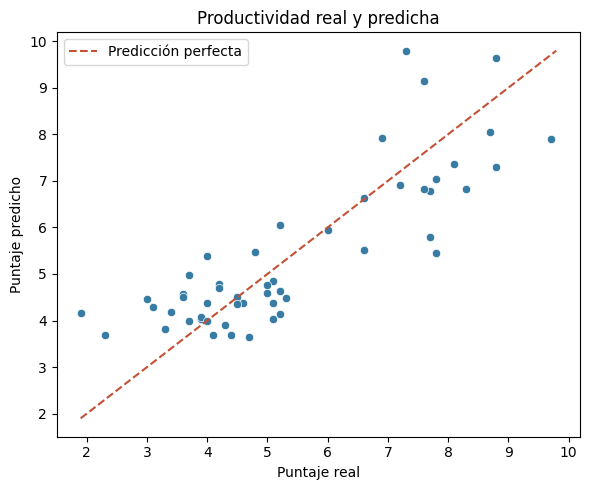

In [35]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    color="#387CA3",
    ax=ax
)

limite_inferior = min(y_test.min(), y_pred.min())
limite_superior = max(y_test.max(), y_pred.max())

ax.plot(
    [limite_inferior, limite_superior],
    [limite_inferior, limite_superior],
    color="#C45136",
    linestyle="--",
    label="Predicción perfecta"
)

ax.set(
    title="Productividad real y predicha",
    xlabel="Puntaje real",
    ylabel="Puntaje predicho"
)

ax.legend()
plt.tight_layout()
plt.show()


### Conclusión del modelo

La regresión lineal supera al baseline en las tres métricas evaluadas: reduce el RMSE de 1,912 a 1,040 y el MAE de 1,545 a 0,847 puntos de productividad. El R² de 0,699 indica que explica aproximadamente el 70 % de la variabilidad de productividad en los 52 registros de prueba.

### Evaluando los mayores errores

In [36]:
errores = X_test.copy()
errores["real"] = y_test
errores["predicho"] = y_pred
errores["error_absoluto"] = abs(y_test - y_pred)

display(
    errores.sort_values("error_absoluto", ascending=False)
    .head(5)
    .round(3)
)

,ai_usage_hours_per_day,time_saved_hours_per_week,real,predicho,error_absoluto
18,9.6,19.4,7.3,9.793,2.493
258,2.9,8.4,7.8,5.460,2.340
204,1.4,2.5,1.9,4.168,2.268
91,3.9,6.8,7.7,5.803,1.897
76,7.0,12.8,9.7,7.893,1.807


## Conclusiones

**Qué aprendimos de los datos:** Observamos asociaciones positivas entre el uso diario de IA, el tiempo ahorrado y la productividad reportada. Los estudiantes y profesionales presentaron promedios similares de productividad y satisfacción.

**Qué tan bien funciona el modelo:** La regresión lineal mejoró las predicciones del baseline, con un MAE de 0,847 puntos, un RMSE de 1,040 y un R² de 0,699 en el conjunto de prueba.

**En qué se equivoca:** El mayor error fue una sobreestimación: el modelo predijo 9,793 puntos frente a 7,3 reales. Entre los otros cuatro casos de mayor error hubo tres subestimaciones y una sobreestimación, con diferencias absolutas de entre 1,807 y 2,340 puntos.

**Qué agregaríamos para mejorarlo:** Evaluaríamos otras variables, como el propósito de uso de IA y el tipo de usuario, y compararíamos la regresión con k-NN. También incorporaríamos validación cruzada para evaluar la estabilidad del desempeño.

**Limitaciones:** Evaluamos el modelo sobre 52 registros de prueba y una única partición. Durante la limpieza del EDA excluimos 31 registros sin datos en las variables principales, conservando los nulos de las demás columnas. Las decisiones de limpieza y la disponibilidad de datos pueden afectar la representatividad de los resultados. Las asociaciones observadas no demuestran relaciones causales.